# Training an autoencoder on the MNIST

This code is trains an autoencoder on the MNIST dataset. 

An autoencoder is a type of neural network that aims to reconstruct its input, by first compressing it with an encoder into a latent space. And then reconstructing it using a decoder.

In this script. The autoencoder is composed of these two small networks. An encoder, and a decoder. The encoder takes the input image, compresses it down to 32 features and passes the encoded representation to the decoder, which then reconstructs the input image. The autoencoder is trained by minizing the mean squared error between the reconstructed image and the original image.

In [5]:
import torch 
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

In [6]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])

train_dataset = datasets.MNIST(root='./data', train=True, download=False, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=False, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [7]:
# Model Structuring

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 32), nn.ReLU())
        self.decoder = nn.Sequential(nn.Linear(32, 128), nn.ReLU(), nn.Linear(128, 784), nn.Sigmoid())

    def forward(self, x):
        x = x.view(x.size(0), -1) # flatten 28x28 image into 748 values
        x = self.encoder(x)
        x = self.decoder(x)

        return(x)

Epoch: 1/10 - Loss: 0.6236
Epoch: 2/10 - Loss: 0.5509
Epoch: 3/10 - Loss: 0.5351
Epoch: 4/10 - Loss: 0.5281
Epoch: 5/10 - Loss: 0.5243
Epoch: 6/10 - Loss: 0.5217
Epoch: 7/10 - Loss: 0.5199
Epoch: 8/10 - Loss: 0.5186
Epoch: 9/10 - Loss: 0.5174
Epoch: 10/10 - Loss: 0.5165


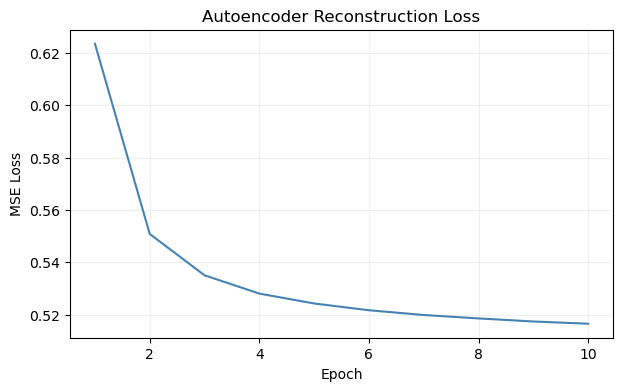

In [8]:
# Training

model = Autoencoder()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
epochs = 10


train_losses = []

for epoch in range(epochs):
    model.train()
    total_loss = 0


    for images, _ in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, images.view(images.size(0), -1))
        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    train_losses.append(total_loss / len(train_loader))

    print(f"Epoch: {epoch+1}/{epochs} - Loss: {total_loss/len(train_loader):.4f}")


plt.figure(figsize=(7, 4))
plt.plot(range(1, epochs + 1), train_losses, color='steelblue')
plt.title('Autoencoder Reconstruction Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.grid(True, alpha=0.2)
plt.show()

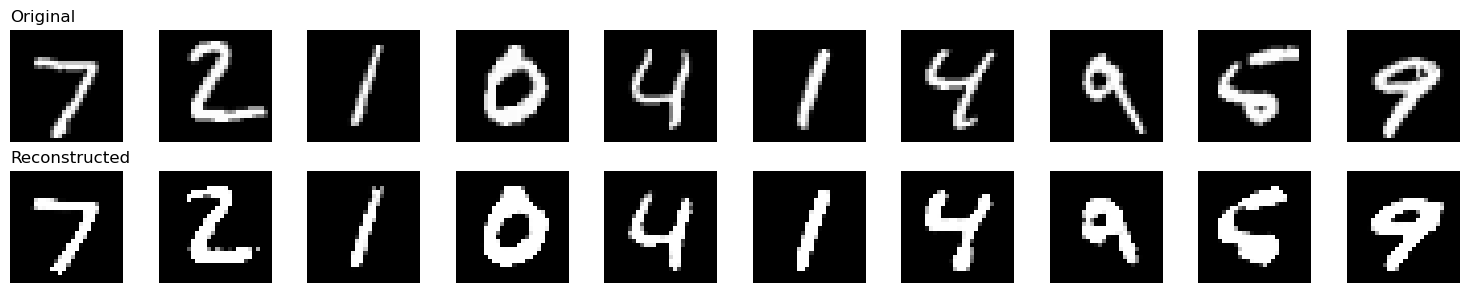

In [9]:
model.eval()

with torch.no_grad():
    sample_images, _ = next(iter(test_loader))
    sample_flat = sample_images.view(sample_images.size(0), -1) # Flatten images
    reconstructed = model(sample_flat)


fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):   
    # Original

    axes[0, i].imshow(sample_images[i].squeeze(), cmap='gray')
    axes[0, i].axis('off')

    # Reconstructed

    axes[1, i].imshow(reconstructed[i].view(28, 28), cmap='gray')
    axes[1, i].axis('off')

axes[0, 0].set_title('Original', loc='left')
axes[1, 0].set_title('Reconstructed', loc='left')

plt.tight_layout()
plt.show()

In [10]:
# # Model

# class Autoencoder(nn.Module):
#     def __init__(self):
#         super().__init__()

#         # Encoder: Compress 748 - 32

#         # nn.sequential is a container that chains layers together in order. 
#         # Instead of writing each step manually in forward, we package them here and they run one after the other automatically
#         self.encoder = nn.Sequential(nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 32), nn.ReLU())
#         # nn.Linear(784, 128), nn.ReLU() is first compression step. Takes 784 pixel values down to 128 neurons, then applies ReLU to kill negatives
#         # nn Linear(128, 32), nn.ReLU() is second compression step. Takes 784 pixel values down to 32. This is the bottleneck. 
#         # Everything the model knows about the image must fit into these 32 numbers.

#         # Decoder: Reconstructs 32 - 784
#         self.decoder = nn.Sequential(nn.Linear(32, 128), nn.ReLU(), nn.Linear(128, 748), nn.Sigmoid())
#         # self.decoder - Mirror image of the encoder, but going in reverse. It expands back up
#         # First epansion step. Takes 32 bottleneck values back up to 128
#         # Final expansion takes 128 values back up to 784 - one value per pixel. 
#         # Sigmoid is used here instead of ReLU, because pixel values must be between 0 and 1. Sigmoid squashes any number into that range.
#         # ReLU would allow values above 1 which makes no sense for pixels


#         def forward(self, x):
#             x = x.view(x.size(0), -1)   # flatten: 28 x 28 - 784 before passing through the encoder
#             x = self.encoder(x)     # Compress to 32. Run through all encoder layers in sequence 784- 128 - 32
#             x = self.decoder(x)     # Reconstruct to 784. Run through all decoder layers in sequence 32 - 128 - 784
#             return(x)



In [11]:
# # Training

# model = Autoencoder()
# # Mean Square Error Loss. It compares each output pixel to the corresponding input pixel, squares the difference and average across all pixels
# # The closer the reconstruction is to the original, the lower this number
# criterion = nn.MSELoss() 

# # Adam optimizer instead of SGD. Adam keeps track of how each weight has been moving and adjusts its learning rate individually
# # Weights that keep changing get a smaller nudge, weights that havent moved get a bigger one. Converge faster than plain SGD
# optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
# epochs = 10


# for epoch in range(epochs):
#     model.train()
#     total_loss = 0


#     # The _ means we are deliberately ignoring the labels. We dont need to know which digit it is, we only need the image itself
#     for images, _ in train_loader:        # _ means we ignore the labels

#         # Flatten the batch of images from (64, 1, 28, 28) to (64,784) before feeding into the model
#         images = images.view(images.size(0), -1)


#         optimizer.zero.grad()
#         # Forward pass - compress to 32, reconstruct to 784
#         outputs = model(images)

#         # Compare the reconstructed output to the original input. Target is the input itself, not a label
#         loss = criterion(outputs, images)      # Compare output to Input
#         loss.backward()
#         optimizer.step()

#         total_loss += loss.item()

#     print(f"Epoch {epoch+1}/{epochs} - Loss: {total_loss/len(train_loader):.4f}")





In [12]:
# # Visualise reconstructions

# model.eval()
# with torch.no_grad():
#     # Grab one batch from the test loader. iter() creates an iterator, next() pulls the first batch from it. We ignore the labels with_.
#     sample_images, _ = next(iter(test_loader))
#     # Run the test images through the autoencoder to get reconstructions
#     sample_flat = sample_images.view(sample_images.size(0), -1)
#     reconstructed = model(sample_flat)

# # Plot original vs reconstructed

# # Create a 2 rows and 10 columns grid. Row 0 will show originals, row 1 will show reconstructions
# fig, axes = plt.subplots(2, 10, figsize=(15, 3))

# for i in range(10):
#     # Original

#     # .squeeze() removes the channel dimension (1, 28, 28) -> (28, 28) so matplotlib can display it as a 2D image. 
#     axes[0, i].imshow(sample_images[i].squeeze(), cmap='gray')
#     axes[0, i].axis('off')

#     # Reconstructed

#     # The reconstruction comes out as a flat vector of 784 values. .view(28, 28) reshapes it back into 28x28 grid so it can displayed as an image
#     axes[1, i].imshow(reconstructed[i].view(28,28), cmap='gray')
#     # Hides the axis tick marks and borders so the images look clean
#     axes[1, i].axis('off')


# axes[0, 0].set_title('Original', loc='left')
# axes[1, 0].set_title('Reconstructed', loc='left')
# plt.tight_layout()
# plt.show()


### Convolutional Autoencoder

In [13]:
class ConvAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        # Encoder
        self.encoder = nn.Sequential(nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), 
                                     nn.MaxPool2d(2, 2), 
                                     nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(),
                                     nn.MaxPool2d(2, 2))

        # Decoder
        self.decoder = nn.Sequential(nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2), nn.ReLU(),
                                     nn.ConvTranspose2d(16, 1, kernel_size=2, stride=2), nn.Sigmoid()
                                     )


    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x
                                     
        

In [14]:
# Training cell

conv_ae = ConvAutoencoder()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(conv_ae.parameters(), lr=0.001)
epochs = 10

conv_ae_losses = []

for epoch in range(epochs):
    conv_ae.train()
    total_loss = 0

    for images, _ in train_loader:
        optimizer.zero_grad()
        outputs = conv_ae(images)       # images stay 4D: (64, 1, 28, 28)
        loss = criterion(outputs, images)   # compare (64, 1, 28, 28) to (64, 1, 28, 28)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    conv_ae_losses.append(avg_loss)
    print(f"Epoch {epoch+1}/{epochs} - Loss:{avg_loss:.4f}")


Epoch 1/10 - Loss:0.5275
Epoch 2/10 - Loss:0.4763
Epoch 3/10 - Loss:0.4736
Epoch 4/10 - Loss:0.4724
Epoch 5/10 - Loss:0.4716
Epoch 6/10 - Loss:0.4710
Epoch 7/10 - Loss:0.4706
Epoch 8/10 - Loss:0.4701
Epoch 9/10 - Loss:0.4698
Epoch 10/10 - Loss:0.4695


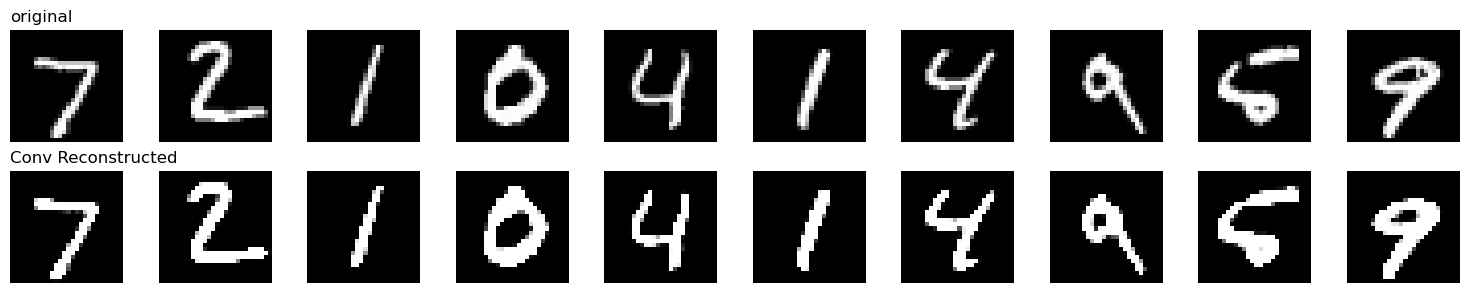

In [15]:
# Visualization cell

conv_ae.eval()
with torch.no_grad():
    sample_images, _ = next(iter(test_loader)) # grab 64 test images
    reconstructed = conv_ae(sample_images)  # pass through, get reconstructions

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(10):
    axes[0, i].imshow(sample_images[i].squeeze(), cmap='gray')
    axes[0, i].axis('off')
    axes[1, i].imshow(reconstructed[i].squeeze(), cmap='gray')
    axes[1, i].axis('off')

axes[0, 0].set_title('original', loc='left')
axes[1, 0].set_title('Conv Reconstructed', loc='left')
plt.tight_layout()
plt.show()

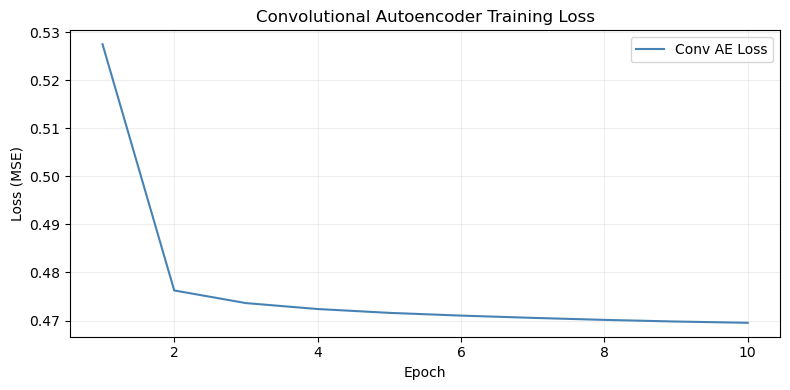

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), conv_ae_losses, color='steelblue', label='Conv AE Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Convolutional Autoencoder Training Loss')
plt.legend()
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

In [17]:
# Save both autoencoders

# state_dict: State Dictionary - Python dictionary containing all the learned weights and biases of the model. Every layer'parameter, stored by name
torch.save(model.state_dict(), 'flat_autoencoder.pth')
# Saves that dictionary to a file on disk. .pth is the conventional extension for Pytorch model files
torch.save(conv_ae.state_dict(), 'conv_autoencoder.pth')
print('Models saved!')

Models saved!


In [18]:
# Load the models back

# Recreate the model architecture first
# Create an empty model first. before filling it.
# load state takes that dictionary of saved weights and puts each one into the correct layer of the model
loaded_flat_ae = Autoencoder() 
loaded_flat_ae.load_state_dict(torch.load('flat_autoencoder.pth'))
# Switch the model to evaluation mode immediately after loading
loaded_flat_ae.eval()

loaded_conv_ae = ConvAutoencoder()
loaded_conv_ae.load_state_dict(torch.load('conv_autoencoder.pth'))
loaded_conv_ae.eval()

print('Models loaded!')

Models loaded!


In [19]:
loaded_conv_ae.eval()
with torch.no_grad():
    sample, _ = next(iter(test_loader))
    output = loaded_conv_ae(sample)
    print(f"Input shape:  {sample.shape}")
    print(f"Output shape: {output.shape}")
    print("Load verified — model is working.")

Input shape:  torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 1, 28, 28])
Load verified — model is working.


In [20]:
# class ConvAutoencoder(nn.Module):
#     def __init__(self):
#         super().__init__()

#         # Encoder
#         # Wraps all encoder layers in one block
#         # Takes 1 raw image (1 channel, 28x28). Applies 16 filters, each 3x3. Padding=1 keeps the size at 28x28. 
#         # Output - 16 feature maps of 28x28 
#         self.encoder = nn.Sequential(nn.Conv2d(1, 16, kernel_size=3, padding=1),        # (1, 28, 28) -> (16, 28, 28)
#                                      # Activation after each conv layer
#                                      nn.ReLU(),

#                                      # Shrinks each feature map by half 28x28 --> 14x14
#                                      nn.MaxPool2d(2, 2),                                # (16, 28, 28) -> (32, 14, 14)

#                                      # Takes those 16 feature maps, produce 32. Keeps size at 14x14, padding = 1
#                                      nn.Conv2d(16, 32, kernel_size=3, padding=1),
#                                      nn.ReLU(), 

#                                      # Half it again
#                                      nn.MaxPool2d(2, 2)       # (32, 14, 14) -> (32, 7, 7)
#                                     )

# # At the end of the encoder: 32 feature maps, each 7x7. Thats the bottleneck (latent space). 
# # The image has been compressed from 784 pixels down to 32x7x7 = 1 568 numbers, but these are rich spatial features


#         # Decoder

#         # # Mirror image of the encoder, but going up instead of down
#         # Reverse MaxPool. stride = 2 doubles spatial size. 7x7 -> 14x14. Channels go from 32->16
#         self.decoder = nn.Sequential(nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2),       # (32, 7, 7) -> (16, 14, 14)
#                                      nn.ReLU(),
#                                      # Doubles again. 14x14->28x28. Channels go from 16->1(back to grayscale)
#                                      nn.ConvTranspose2d(16, 1, kernel_size=2, stride=2),        # (16, 14, 14) -> (1, 28, 28)
#                                      # Squashes every pixel to 0-1. So pixel values match the input range
#                                      nn.Sigmoid()
#                                      )

#     # There is x.view here. We are staying in 4D tensor shape the whole time (batch, channels, height, width). Conv layers expect that shape, we never need to flatten
#     def forward(self, x):
#         x = self.encoder(x)
#         x = self.decoder(x)
#         return x


    

In [21]:
# # A training cell

# conv_ae = ConvAutoencoder()
# criterion = nn.MSELoss()
# optimizer = torch.optim.Adam(conv_ae.parameters(), lr=0.001)
# epochs = 10
# conv_ae_losses = []

# for epoch in range(epochs):
#     conv_train()
#     total_loss = 0

#     for images, _ in train_loader:
#         optimizer.zero_grad()
#         outputs = conv_ae(images)
#         loss = criterion(outputs, images) # no .view needed, Both outputs and images are already same shape (64, 1, 28, 28)
#         loss.backward()
#         optimizer.step()
#         total_loss += loss.item()

#     avg_loss = total_loss / len(train_loader)
#     conv_ae_losses.append(avg_loss)
#     print(f"Epoch {epoch+1}/{epochs} - Loss: {avg_loss:.4f}")

### Latent Space Extraction + PCA and t-SNE

In [22]:
conv_ae.eval()
all_latents = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        latents = conv_ae.encoder(images)
        latents = latents.view(latents.size(0), -1)

        all_latents.append(latents)
        all_labels.append(labels)

all_latents = torch.cat(all_latents, dim=0).numpy()
all_labels = torch.cat(all_labels, dim=0).numpy()

print(f"Latent Shape {all_latents.shape}")
print(f"Labels Shape {all_labels.shape}")



Latent Shape (10000, 1568)
Labels Shape (10000,)


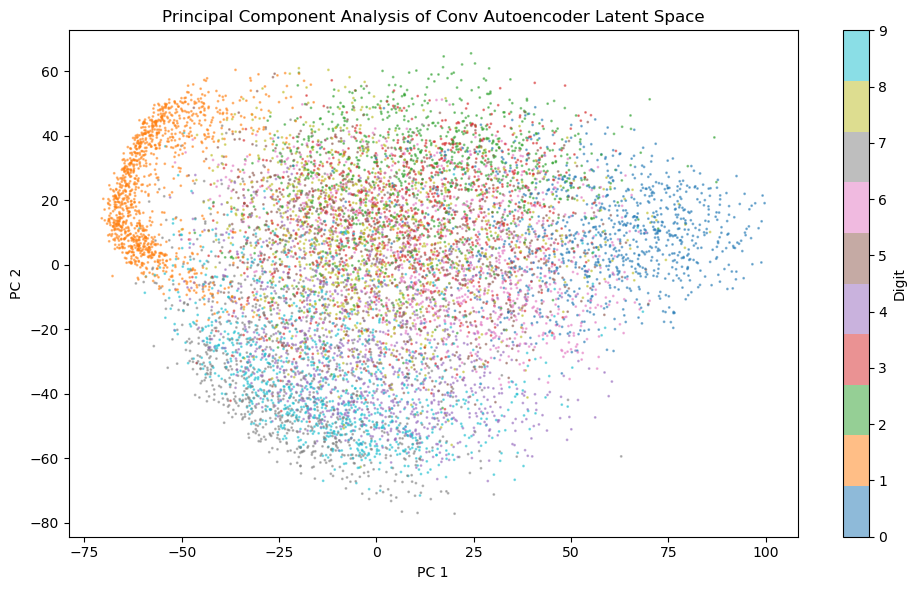

In [ ]:
# PCA

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

latents_pca = pca.fit_transform(all_latents)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(latents_pca[:, 0], latents_pca[:, 1], c=all_labels, cmap='tab10', s=1, alpha=0.5)
plt.colorbar(scatter, label='Digit')
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.title('Principal Component Analysis of Conv Autoencoder Latent Space')
plt.tight_layout()
plt.show()


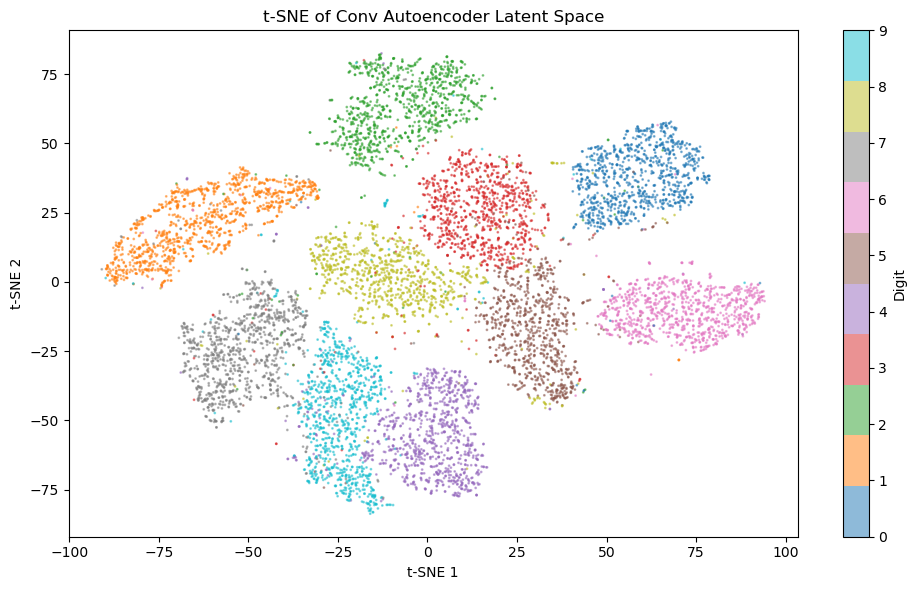

In [31]:
# TSNE 

from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
tsne_latents = tsne.fit_transform(all_latents)  #(10000, 1568) -> (10000, 2)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(tsne_latents[:, 0], tsne_latents[:, 1], c=all_labels, cmap='tab10', s=1, alpha=0.5)
plt.colorbar(scatter, label='Digit')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.title('t-SNE of Conv Autoencoder Latent Space')
plt.tight_layout()
plt.show()

In [23]:
# # Did the encoder learn to group digits together, evenn tough it was never told what digit it is?

# # Extract latent vectors from the conv autoencoder


# conv_ae.eval()
# all_latents = []
# all_labels = []

# with torch.no_grad():
#     for images, labels in test_loader:
#         # we call only the encoder. not full model. stop halfway through and grab the compressed representation, not the reconstruction.
#         latents = conv_ae.encoder(images)   # run encoder only
#         # Encoder output is (64, 32, 7, 7). We flatten it to (64, 1568), PCA & t-SNE expect flat vector per sample
#         latents = latents.view(latents.size(0), -1) # flatten : (64, 32, 7, 7) -> (64, 1568)
#         # Collect all batches into a list
#         all_latents.append(latents)
#         all_labels.append(labels)


# # stitches all the batches back into one big tensor. dim=0 means we're stacking along sample axis. Goes from a list of (64, 1568) tensors to one (10000, 1568) tensor.
# # numpy() converts from PyTorch tensor to a numpy array, which is what PCA and t-SNE expect
# all_latents = torch.cat(all_latents, dim=0).numpy()     # (100000, 1568)
# all_labels = torch.cat(all_labels, dim=0).numpy()       # (10000,)

# print(f"Latent shape: {all_latents.shape}")
# print(f"Labels shape: {all_labels.shape}")


In [29]:
# # PCA cell

# from sklearn.decomposition import PCA

# # Tell PCA to compress the 1568 dimensional latent vectors down to just 2 dimensions so we can plot them
# pca = PCA(n_components=2)

# # PCA finds the two directions in 1568D space that capture the most variations across all 10000 samples, then projects everything onto those directions
# latents_pca = pca.fit_transform(all_latents)    # (10000, 1568) -> (10000, 2)

# plt.figure(figsize=(8, 6))
# # c=all_labels - colors each dot by its digit label(0-9). To check what the encoder learnt on its own'
# # cmap=tab10 - a colormap with 10 distinct colours, 1 per digit
# #s=1, alpha-0.5 - small dots, slightly transparent. With 10000points we need this or the plot is just solid blob
# # [:,0] all rows, first column - First principal component (xaxis)
# # [:,1] is the second (yaxis)
# scatter = plt.scatter(latents_pca[:, 0], latents_pca[:, 1], c=all_labels, cmap='tab10', s=1, alpha=0.5)
# plt.colorbar(scatter, label='Digit')
# plt.title('PCA of Conv Autoencoder Latent Space')
# plt.xlabel('PC 1')
# plt.ylabel('PC 2')
# plt.tight_layout()
# plt.show()

In [ ]:
# from sklearn.manifold import TSNE

# # t-SNE compresses to 2D like PCA, but using a different method. It tries to keep nearby points in high dimensional space nearby in 2D
# # random_state=42 makes the results reproducible, perplexity=30 is roughly "how may neighbours to consider". 30 is standard default
# tsne = TSNE(n_components=2, random_state=42, perplexity=30)
# # fit_transform here does not have separate fit and transform. It computes the 2D positions for these specific points and thats it.
# latents_sne = tsne.fit_transform(all_latents) # (10000, 1568) -> (10000, 2)

# plt.figure(figsize=(10, 6))
# scatter = plt.scatter(latents_sne[:, 0], latents_sne[:, 1], c=all_labels, cmap='tab10', s=1, alpha=0.5)
# plt.colorbar(scatter, label='Digit')
# plt.xlabel('t-SNE 1')
# plt.ylabel('t-SNE 2')
# plt.title('t-SNE of Conv Autoencoder Latent Space')
# plt.tight_layout()
# plt.show()